# README
- **Author**: 詹明翰、謝子詮、曾翊涵（沿用已確認共同作者，不推定個別分工）
- **Created At**: 2026-11-26
- **Last Modified At**: 2026-11-26

## What does this file do?
Unit 1.4都市計畫來源／版本及CRS驗證：官方ZIP逐檔與本機比對、metadata證據鏈、原始坐標、合理候選CRS及共同特徵位置診斷。
沿用Unit 0.5品質紀錄，不正式修復、刪重、分類、Overlay或計算任何分區面積。假設CRS只指定於記憶體診斷副本。

## What does this file take?
前11個原始配套hash固定於Unit 0.5，讀取精確路徑；其餘為銜接文件與新增官方來源包。
- `data/raw/細計-面.shp`；SHA-256 `67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee`
- `data/raw/細計-面.shx`；SHA-256 `277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69`
- `data/raw/細計-面.dbf`；SHA-256 `29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4`
- `data/raw/細計-文.shp`；SHA-256 `fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731`
- `data/raw/細計-文.shx`；SHA-256 `32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760`
- `data/raw/細計-文.dbf`；SHA-256 `eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be`
- `data/raw/G97_A_CAVLGE_P.shp`；SHA-256 `f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc`
- `data/raw/G97_A_CAVLGE_P.shx`；SHA-256 `ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e`
- `data/raw/G97_A_CAVLGE_P.dbf`；SHA-256 `2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577`
- `data/raw/G97_A_CAVLGE_P.prj`；SHA-256 `8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5`
- `data/raw/G97_A_CAVLGE_P.cpg`；SHA-256 `3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824`
- `data/raw/taipei_urban_planning_raw_documentation.ipynb`；SHA-256 `bb3dd6bca248ce866b30766762d100cd926e7cbed30f0165381f531709b8aa8f`
- `data/code/taipei_village_boundary_validation.ipynb`；SHA-256 `662dbee2dc42c3552b12628a1e89fcc81b07155c225277117f50d07e0145a343`
- `data/code/taipei_population_validation.ipynb`；SHA-256 `e26ff652ccfa2113db041322a99a000d8cb6d71acccdab66c35448fcddaab7d8`
- `data/processed/village_crosswalk.csv`；SHA-256 `dd9e762419c302cf5b4bb19daad2673d7d54d0bb750204e7e33ecbf1a9983f69`
- `data/raw/unit14_urban_planning_evidence.zip`；SHA-256 `695e15f7230c076b2b827f72b4337273ff795f6fc7e9c52680641c972dd72730`
- `data/raw/unit14_urban_planning_evidence_documentation.ipynb`；SHA-256 `ec2e9b002441d10b26b426f6d43cf6c5dd9c598ca058cda81a2f9f058e02dc55`

[都市計畫raw說明](../raw/taipei_urban_planning_raw_documentation.ipynb)、[Unit 1.2里界驗證](taipei_village_boundary_validation.ipynb)、[Unit 1.3人口驗證](taipei_population_validation.ipynb)、[官方證據包說明](../raw/unit14_urban_planning_evidence_documentation.ipynb)。
[PROJECT.md](../../PROJECT.md)為已授權更新的決策脈絡，不綁其編輯前hash。

## What does this file output?
本Notebook保存實際診斷表及4張空間品質圖；Output key `urban_planning_crs_validation_documentation`，Role為驗證文件。
無正式processed圖資或分區面積表；圖及摘要另存Git忽略的`data/temp/unit14_validation/`供核對，正式閱讀依Notebook內嵌輸出。
官方ZIP及JSON的原始bytes封存於新raw證據包，可離線重現，不依賴原暫存下載或即時服務。
Verification status依實際全cell執行與末尾hash／geometry保護檢查；未完成的CRS認證與歷史版本仍標未知。


In [1]:
from pathlib import Path
from datetime import datetime,timezone,date
import hashlib,json,io,zipfile,sys,os,platform,struct
import numpy as np
import pandas as pd
from IPython.display import display,Markdown
def find_root():
    for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
        if (p/'AGENTS.md').is_file() and (p/'templates').is_dir():return p
    raise FileNotFoundError('Open within student project containing AGENTS.md and templates/.')
ROOT=find_root();TEMP=ROOT/'data/temp/unit14_validation';TEMP.mkdir(parents=True,exist_ok=True)
assert Path(sys.executable).resolve()==(ROOT/'.venv/Scripts/python.exe').resolve()
assert sys.prefix!=sys.base_prefix
os.environ['PROJ_NETWORK']='OFF'
def file(relative,area='data',must_exist=True):
    rel=Path(relative)
    if rel.is_absolute() or '..' in rel.parts:raise ValueError('Exact project-relative path required')
    p=(ROOT/rel).resolve()
    if not p.is_relative_to((ROOT/area).resolve()):raise ValueError('Path outside intended project area')
    if must_exist and not p.is_file():raise FileNotFoundError(relative)
    return p
def sha(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
def verify(expected):
    rows=[]
    for relative,digest in expected.items():
        p=file(relative);assert sha(p)==digest,f'Input changed; stop and inspect version: {relative}'
        rows.append({'path':relative,'bytes':p.stat().st_size,'sha256':digest})
    return pd.DataFrame(rows)
def show(title,table,block=20):
    display(Markdown('**'+title+'**'))
    if not len(table):display(Markdown('無符合紀錄。'))
    for start in range(0,len(table),block):display(table.iloc[start:start+block])
pd.set_option('display.max_colwidth',110)
print({'python':platform.python_version(),'project_venv':True,'network_in_notebook':'none'})

EXPECTED_SHA256={'data/raw/細計-面.shp': '67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee', 'data/raw/細計-面.shx': '277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69', 'data/raw/細計-面.dbf': '29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4', 'data/raw/細計-文.shp': 'fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731', 'data/raw/細計-文.shx': '32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760', 'data/raw/細計-文.dbf': 'eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be', 'data/raw/G97_A_CAVLGE_P.shp': 'f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc', 'data/raw/G97_A_CAVLGE_P.shx': 'ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e', 'data/raw/G97_A_CAVLGE_P.dbf': '2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577', 'data/raw/G97_A_CAVLGE_P.prj': '8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5', 'data/raw/G97_A_CAVLGE_P.cpg': '3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824', 'data/raw/taipei_urban_planning_raw_documentation.ipynb': 'bb3dd6bca248ce866b30766762d100cd926e7cbed30f0165381f531709b8aa8f', 'data/code/taipei_village_boundary_validation.ipynb': '662dbee2dc42c3552b12628a1e89fcc81b07155c225277117f50d07e0145a343', 'data/code/taipei_population_validation.ipynb': 'e26ff652ccfa2113db041322a99a000d8cb6d71acccdab66c35448fcddaab7d8', 'data/processed/village_crosswalk.csv': 'dd9e762419c302cf5b4bb19daad2673d7d54d0bb750204e7e33ecbf1a9983f69', 'data/raw/unit14_urban_planning_evidence.zip': '695e15f7230c076b2b827f72b4337273ff795f6fc7e9c52680641c972dd72730', 'data/raw/unit14_urban_planning_evidence_documentation.ipynb': 'ec2e9b002441d10b26b426f6d43cf6c5dd9c598ca058cda81a2f9f058e02dc55'}
show('表1：原始配套及銜接文件hash',verify(EXPECTED_SHA256),block=6)
import geopandas as gpd
import shapely
from shapely.geometry import Polygon
from pyproj import CRS
from pyproj.transformer import TransformerGroup
from importlib import metadata
layers={name:gpd.read_file(file('data/raw/'+name+'.shp'),engine='pyogrio',encoding='cp950') for name in ['細計-面','細計-文']}
village=gpd.read_file(file('data/raw/G97_A_CAVLGE_P.shp'),engine='pyogrio',encoding='utf-8')
assert village.crs.to_epsg()==3826
assert all(g.crs is None for g in layers.values())
original_wkb={name:g.geometry.to_wkb().copy() for name,g in layers.items()}
print({'packages':{k:metadata.version(k) for k in ['geopandas','shapely','pyproj','pyogrio','matplotlib']},
       'GEOS':shapely.geos_version_string,'original_plan_CRS':[str(g.crs) for g in layers.values()],
       'source_hashes_match_Unit_0_5':True,'existing_notebooks_executed':False})


{'python': '3.12.2', 'project_venv': True, 'network_in_notebook': 'none'}


**表1：原始配套及銜接文件hash**

,path,bytes,sha256
0,data/raw/細計-面.shp,7556848,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee
1,data/raw/細計-面.shx,124244,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69
2,data/raw/細計-面.dbf,13982136,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4
3,data/raw/細計-文.shp,184,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731
4,data/raw/細計-文.shx,124,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760
5,data/raw/細計-文.dbf,3121,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be


,path,bytes,sha256
6,data/raw/G97_A_CAVLGE_P.shp,765784,f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc
7,data/raw/G97_A_CAVLGE_P.shx,3748,ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e
8,data/raw/G97_A_CAVLGE_P.dbf,272706,2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577
9,data/raw/G97_A_CAVLGE_P.prj,399,8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5
10,data/raw/G97_A_CAVLGE_P.cpg,5,3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824
11,data/raw/taipei_urban_planning_raw_documentation.ipynb,283788,bb3dd6bca248ce866b30766762d100cd926e7cbed30f0165381f531709b8aa8f


,path,bytes,sha256
12,data/code/taipei_village_boundary_validation.ipynb,1802468,662dbee2dc42c3552b12628a1e89fcc81b07155c225277117f50d07e0145a343
13,data/code/taipei_population_validation.ipynb,142657,e26ff652ccfa2113db041322a99a000d8cb6d71acccdab66c35448fcddaab7d8
14,data/processed/village_crosswalk.csv,362330,dd9e762419c302cf5b4bb19daad2673d7d54d0bb750204e7e33ecbf1a9983f69
15,data/raw/unit14_urban_planning_evidence.zip,6177243,695e15f7230c076b2b827f72b4337273ff795f6fc7e9c52680641c972dd72730
16,data/raw/unit14_urban_planning_evidence_documentation.ipynb,63002,ec2e9b002441d10b26b426f6d43cf6c5dd9c598ca058cda81a2f9f058e02dc55


{'packages': {'geopandas': '1.2.0', 'shapely': '2.2.0', 'pyproj': '3.8.0', 'pyogrio': '0.13.0', 'matplotlib': '3.11.2'}, 'GEOS': '3.14.1', 'original_plan_CRS': ['None', 'None'], 'source_hashes_match_Unit_0_5': True, 'existing_notebooks_executed': False}


## 1. Unit 1.3 Review Revision — Policy Overrides Historical Trial
學生本次Revision優先於附件舊敏感度要求：糖廍里配對已接受，與其餘455里同規則納主要人口、都市環境及後續整合；不另做排除敏感度、不再查碼。
標準名稱糖廍里；原人口糖?里及里界糖蔀里不改。Crosswalk的provisional_match忠實保留證據強度，不構成分析資格限制，也不得僅因此將密度／人口特徵設NA。
舊Unit 1.3記憶體試算的910可用＋2待審與NA是當時紀錄，不是現行規則；不重跑、不覆寫舊Notebook及crosswalk。
B1仍為密度、65+、0–14三候選；年度12月、合併24月重算，其他人口特徵仍補充選項，事故分群資格不受此名稱差異影響。


In [2]:
crosswalk=pd.read_csv(file('data/processed/village_crosswalk.csv'),dtype='string',encoding='utf-8-sig',keep_default_na=False)
tangbu=crosswalk.loc[crosswalk.village_id.eq('6300700015')]
assert len(crosswalk)==456 and len(tangbu)==1
assert tangbu.verification_status.iloc[0]=='provisional_match' and tangbu.standard_village_name.iloc[0]=='糖廍里'
show('表2：只讀核對原crosswalk，狀態不變',tangbu[['village_id','population_code','boundary_code','population_village_name','boundary_village_name','standard_village_name','verification_status']])
ACCEPTED_REVISION={'Tangbu_included_in_main_population_and_environment_analysis':True,
  'same_rules_as_other_455_villages':True,'exclude_Tangbu_sensitivity_required':False,
  'further_Tangbu_code_investigation_required':False,'provisional_status_is_not_an_exclusion_rule':True,
  'Unit_1_3_rerun':False,'crosswalk_modified':False}
print(ACCEPTED_REVISION)


**表2：只讀核對原crosswalk，狀態不變**

,village_id,population_code,boundary_code,population_village_name,boundary_village_name,standard_village_name,verification_status
239,6300700015,63000070015,6300700015,糖?里,糖蔀里,糖廍里,provisional_match


{'Tangbu_included_in_main_population_and_environment_analysis': True, 'same_rules_as_other_455_villages': True, 'exclude_Tangbu_sensitivity_required': False, 'further_Tangbu_code_investigation_required': False, 'provisional_status_is_not_an_exclusion_rule': True, 'Unit_1_3_rerun': False, 'crosswalk_modified': False}


## 2. Official Source, Resource Contents and Dates
[官方資料頁](https://data.taipei/dataset/detail?id=3bab0a01-7936-4218-8cb5-f74dfcb43dda)為都發局「臺北市都市計畫使用分區圖」，同頁提供主要計畫／細部計畫SHP；頁面描述內容更新至114年1月。
細計資源發布更新2026-04-09 11:49:14、主計11:49:21；不是各都市計畫法定生效日。
本次取得完整官方兩ZIP與metadata，未替換本機六檔。ZIP、DBF、檔案系統及下載時間均分開記錄，檔名不當作CRS或法律版本。


In [3]:
evidence=zipfile.ZipFile(file('data/raw/unit14_urban_planning_evidence.zip'))
source_manifest=json.loads(evidence.read('source_manifest.json'))
for item in source_manifest:assert hashlib.sha256(evidence.read(item['member'])).hexdigest()==item['sha256']
show('表3：官方來源、版本、實際取得時間與逐檔hash',pd.DataFrame(source_manifest),block=4)
show('表4：失敗請求及不採用理由',pd.DataFrame(json.loads(evidence.read('failed_requests.json'))))
official_zip={name:zipfile.ZipFile(io.BytesIO(evidence.read(member))) for name,member in
              [('細計','official_detailed_plan.zip'),('主計','official_main_plan.zip')]}
contents=[];header_rows=[]
for plan,z in official_zip.items():
    for info in z.infolist():
        b=z.read(info.filename)
        contents.append({'plan':plan,'member':info.filename,'bytes':len(b),'sha256':hashlib.sha256(b).hexdigest(),'ZIP_member_time':str(info.date_time)})
        if info.filename.endswith('.dbf'):
            local=file('data/raw/'+info.filename) if plan=='細計' else None
            header_rows.append({'source':plan,'member':info.filename,'DBF_version_byte':int(b[0]),
               'DBF_header_write_date':str(date(1900+b[1],b[2],b[3])),'DBF_record_count':int.from_bytes(b[4:8],'little'),
               'local_filesystem_mtime_UTC':datetime.fromtimestamp(local.stat().st_mtime,tz=timezone.utc).isoformat() if local else 'not local research input',
               'effective_date':'unconfirmed','original_local_download_date':'unconfirmed'})
        if info.filename.endswith('.shp'):
            assert struct.unpack('>i',b[:4])[0]==9994
            header_rows.append({'source':plan,'member':info.filename,'SHP_version':struct.unpack('<i',b[28:32])[0],
                 'SHP_type':struct.unpack('<i',b[32:36])[0],'SHP_header_bounds_Xmin_Ymin_Xmax_Ymax':str(struct.unpack('<4d',b[36:68])),
                 'SHP_header_has_CRS_or_effective_date':False})
show('表5：主／細計完整配套清單',pd.DataFrame(contents),block=12)
show('表6：SHP與DBF原始header；日期語意不混同',pd.DataFrame(header_rows),block=8)
assert all(not any(i.filename.lower().endswith(('.prj','.cpg','.xml','.md','.txt')) for i in z.infolist()) for z in official_zip.values())
print({'official_archives_have_projection_definition':False,'content_date_on_source_page':'2025-01',
       'resource_update_date':'2026-04-09','local_plan_effective_date':'unconfirmed'})


**表3：官方來源、版本、實際取得時間與逐檔hash**

,member,source_url,version,retrieved_at_utc,bytes,sha256,response_url,content_type,http_last_modified,status
0,dataset_page.html,https://data.taipei/dataset/detail?id=3bab0a01-7936-4218-8cb5-f74dfcb43dda,dataset metadata viewed 2026-11-26,2026-11-26T06:48:42.027953+00:00,85871,a13992dae629b7520cd6c78e88f9ed6b87f900e16b01eddcfbdffe98bd4663d9,https://data.taipei/dataset/detail?id=3bab0a01-7936-4218-8cb5-f74dfcb43dda,text/html;charset=utf-8,,NaN
1,official_detailed_plan.zip,https://data.taipei/api/frontstage/tpeod/dataset/resource.download?rid=0cb6e68a-87c1-4846-b766-bcde3ebe179c,全市細計; resource updated 2026-04-09 11:49:14; page describes content through 114年1月,2026-11-26T06:49:06.900307+00:00,4187541,d89e3ab3dcdc60de2b2b83987c0774d87ae3037d53af2adf5a28f47b3a44a21b,https://data.taipei/api/frontstage/tpeod/dataset/resource.download?rid=0cb6e68a-87c1-4846-b766-bcde3ebe179c,application/zip;charset=UTF-8,,NaN
2,official_main_plan.zip,https://data.taipei/api/frontstage/tpeod/dataset/resource.download?rid=10196e7d-2460-4b8a-b1d2-84001d09d7a4,全市主計; resource updated 2026-04-09 11:49:21; page describes content through 114年1月,2026-11-26T06:49:25.265064+00:00,2008868,7abe625f329454e1079bc449d3c71f54c7e58eeafecdb71eb2e64f88f3c7f146,https://data.taipei/api/frontstage/tpeod/dataset/resource.download?rid=10196e7d-2460-4b8a-b1d2-84001d09d7a4,application/zip;charset=UTF-8,,NaN
3,udd_webgis_index.html,https://webgis.udd.gov.taipei/,"official GIS application; current capture, not certified as the same source geometry",2026-11-26T06:49:25.416525+00:00,137,6c9520fba79d49c630383cb9c9360f2bc6afc7bae1ef0f437dab61d1aa85b227,https://webgis.udd.gov.taipei/,text/html,"Sat, 27 Jul 2024 16:38:14 GMT",NaN


,member,source_url,version,retrieved_at_utc,bytes,sha256,response_url,content_type,http_last_modified,status
4,UrbanPlan2_MapServer.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer?f=pjson,current service metadata; linkage to local SHP not certified,2026-11-26T06:50:16.026074+00:00,2384,2310eacb6c1b7b1e444b4d3187b64492cf04a86148c9095cb8adadd0d763af29,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer?f=pjson,text/plain;charset=UTF-8,,retrieved
5,UrbanPlan2_layer0.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/0?f=pjson,current annotation layer metadata,2026-11-26T06:50:16.126208+00:00,4634,bd5c7683710df876a85b45e7020fb00e0c076d9e23ea95d9a8a91395ac3623ae,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/0?f=pjson,text/plain;charset=UTF-8,,retrieved
6,UrbanPlan2_layer2.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2?f=pjson,current large-scale zoning layer metadata,2026-11-26T06:50:20.166449+00:00,98165,1c383562c2dbeb7fe47f41bca3eeb5c3be1d8e11908149d29fde50a716e58975,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2?f=pjson,text/plain;charset=UTF-8,,retrieved
7,planning_law_chapter2.html,https://laws.gov.taipei/law/LawSearch/LawChapterArticle/FL003591?chapterno=2,"official published legal text, articles 15/22 as planning-level context only",2026-11-26T06:50:25.141530+00:00,60012,3e579cb215a6faa518cadf65c8ce58c33cc204fcdde7482f1fa58f09216251be,https://laws.gov.taipei/law/LawSearch/LawChapterArticle/FL003591?chapterno=2,text/html; charset=utf-8,,retrieved


,member,source_url,version,retrieved_at_utc,bytes,sha256,response_url,content_type,http_last_modified,status
8,udd_overall_review.html,https://udd.gov.taipei/events/f3gxcu9-10720,official plan review announcements; not a historical citywide SHP archive,2026-11-26T06:50:27.377899+00:00,64411,43473cc63689ca98759fb403f785ee2e4df431d967ba33257f6c6880ea4e22e6,https://udd.gov.taipei/events/f3gxcu9-10720,text/html; charset=utf-8,,retrieved
9,layer2_count.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2/query?where=1%3D1&return...,"current service; query inputs recorded in URL; outSR3826 is requested output, not source-CRS proof",2026-11-26T06:51:30.322289+00:00,15,949cf8bfaff08e201caccca39eebb09fecef5245ae6970c6d60ce0ee96f80729,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2/query?where=1%3D1&return...,application/json;charset=UTF-8,NaN,retrieved
10,layer2_controls.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2/query?where=%E7%B7%A8%E8...,"current service; query inputs recorded in URL; outSR3826 is requested output, not source-CRS proof",2026-11-26T06:51:30.497962+00:00,16419,62104e9f4c532d430e99e37e6ef806e574dc5f08a4984f8562a075bd15f75fb2,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2/query?where=%E7%B7%A8%E8...,application/json;charset=UTF-8,NaN,retrieved
11,layer0_controls.json,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/0/query?where=%E7%B7%A8%E8...,"current service; query inputs recorded in URL; outSR3826 is requested output, not source-CRS proof",2026-11-26T06:51:30.626538+00:00,1363,045ea75bcc3277ed0d50973072c7cc0be83dacb216aff538006d2e4cb9522e67,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/0/query?where=%E7%B7%A8%E8...,application/json;charset=UTF-8,NaN,retrieved


**表4：失敗請求及不採用理由**

,member,source_url,version,attempted_at_utc,status,error,record_source
0,national_upload_manual112.pdf,https://ngis.tcd.gov.tw/UpLoadData/國家地理資訊系統都市計畫圖資上傳作業手冊112年版.pdf,112年版 general upload guidance; not proof of local CRS,2026-11-26T06:50:23.459511+00:00,failed,AssertionError: national_upload_manual112.pdf,NaN
1,NaN,https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/0/query?where=%E5%88%86%E5...,NaN,NaN,failed,ArcGIS error 400: Unable to complete operation.,Unit 1.4 execution log; failed body was not archived and is not used as CRS evidence


**表5：主／細計完整配套清單**

,plan,member,bytes,sha256,ZIP_member_time
0,細計,細計-文.dbf,3121,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be,"(2026, 4, 9, 10, 39, 50)"
1,細計,細計-文.shp,184,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731,"(2026, 4, 9, 10, 39, 50)"
2,細計,細計-文.shx,124,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760,"(2026, 4, 9, 10, 39, 50)"
3,細計,細計-面.dbf,13982136,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4,"(2026, 4, 9, 10, 39, 50)"
4,細計,細計-面.shp,7556848,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee,"(2026, 4, 9, 10, 39, 50)"
5,細計,細計-面.shx,124244,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69,"(2026, 4, 9, 10, 39, 50)"
6,主計,主計圖-文.dbf,3445842,e8c8d9f3dca9090be6e7defc68acbf387484212d1be9e739e4cab0e121417b2c,"(2026, 4, 9, 10, 39, 22)"
7,主計,主計圖-文.shp,107172,6f9cfae833170e475b7c00275709fad568d8e7688ab531034c4aa24f2ab545d9,"(2026, 4, 9, 10, 39, 22)"
8,主計,主計圖-文.shx,30692,3374ff95b3e87bfa4e3892c10f2c0a07c73d7badf91cf376105734131df0c481,"(2026, 4, 9, 10, 39, 22)"
9,主計,主計圖-面.dbf,3460258,a8c7eef033837d998672368a8266409d6f461dea6cb73cd810ce175223c910f9,"(2026, 4, 9, 10, 39, 20)"


**表6：SHP與DBF原始header；日期語意不混同**

,source,member,DBF_version_byte,DBF_header_write_date,DBF_record_count,local_filesystem_mtime_UTC,effective_date,original_local_download_date,SHP_version,SHP_type,SHP_header_bounds_Xmin_Ymin_Xmax_Ymax,SHP_header_has_CRS_or_effective_date
0,細計,細計-文.dbf,3.0,2026-04-09,3.0,2026-11-25T12:21:34.167142+00:00,unconfirmed,unconfirmed,NaN,NaN,NaN,NaN
1,細計,細計-文.shp,NaN,NaN,NaN,NaN,NaN,NaN,1000.0,1.0,"(294769.294, 2759511.553, 319676.13, 2790593.596)",False
2,細計,細計-面.dbf,3.0,2026-04-09,15518.0,2026-11-25T12:21:34.202147+00:00,unconfirmed,unconfirmed,NaN,NaN,NaN,NaN
3,細計,細計-面.shp,NaN,NaN,NaN,NaN,NaN,NaN,1000.0,5.0,"(294769.294, 2759511.553, 319676.13, 2790593.596)",False
4,主計,主計圖-文.dbf,3.0,2026-04-09,3824.0,not local research input,unconfirmed,unconfirmed,NaN,NaN,NaN,NaN
5,主計,主計圖-文.shp,NaN,NaN,NaN,NaN,NaN,NaN,1000.0,1.0,"(294769.294, 2759511.553, 319676.13, 2790593.596)",False
6,主計,主計圖-面.dbf,3.0,2026-04-09,3840.0,not local research input,unconfirmed,unconfirmed,NaN,NaN,NaN,NaN
7,主計,主計圖-面.shp,NaN,NaN,NaN,NaN,NaN,NaN,1000.0,5.0,"(294769.294, 2759511.553, 319676.13, 2790593.596)",False


{'official_archives_have_projection_definition': False, 'content_date_on_source_page': '2025-01', 'resource_update_date': '2026-04-09', 'local_plan_effective_date': 'unconfirmed'}


## 3. Official Downloads versus Local Files
A＝相同bytes；B＝bytes不同但全幾何／屬性可證相同；C＝同族不同發布內容／版本；D＝不同資料或無法建立對應。
六個本機細計配套均與官方下載逐bytes比對；再獨立讀取官方ZIP檢查schema、屬性、WKB及bounds。
主計是不同規劃層級，不直接替換細計；服務是另一發布視圖，完整版本／日期未認證，不因欄名或部分特徵相同而認定全檔相同。


In [4]:
comparisons=[]
for member in official_zip['細計'].namelist():
    b=official_zip['細計'].read(member);p=file('data/raw/'+member)
    same=p.read_bytes()==b
    comparisons.append({'local_path':'data/raw/'+member,'official_member':member,'local_bytes':p.stat().st_size,
                        'official_bytes':len(b),'local_sha256':sha(p),'official_sha256':hashlib.sha256(b).hexdigest(),'same_bytes':same,'relationship_grade':'A' if same else 'requires semantic check'})
show('表7：官方細計與本機六檔逐檔比較',pd.DataFrame(comparisons),block=6)
assert all(row['same_bytes'] for row in comparisons)
runtime=TEMP/'official_runtime';runtime.mkdir(parents=True,exist_ok=True)
for member in ['official_detailed_plan.zip','official_main_plan.zip']:
    p=runtime/member;b=evidence.read(member)
    if p.exists():assert p.read_bytes()==b
    else:p.write_bytes(b)
def read_official(package,member):
    return gpd.read_file('/vsizip/'+(runtime/package).as_posix()+'/'+member,engine='pyogrio',encoding='cp950')
semantic=[]
for name,g in layers.items():
    other=read_official('official_detailed_plan.zip',name+'.shp')
    pd.testing.assert_frame_equal(g.drop(columns='geometry'),other.drop(columns='geometry'))
    wkb_equal=g.geometry.to_wkb().equals(other.geometry.to_wkb())
    assert wkb_equal and np.array_equal(g.total_bounds,other.total_bounds)
    semantic.append({'layer':name,'rows':len(g),'types':str(g.geom_type.value_counts().to_dict()),
       'columns_and_dtypes_same':True,'all_attribute_records_same':True,'all_geometry_WKB_same':wkb_equal,
       'bounds_same':True,'official_reader_CRS':str(other.crs)})
show('表8：獨立讀取官方細計的全內容核對',pd.DataFrame(semantic))
main_layers={name:read_official('official_main_plan.zip',name+'.shp') for name in ['主計圖-面','主計圖-文']}
main_info=pd.DataFrame([{'layer':name,'rows':len(g),'geometry_types':str(g.geom_type.value_counts().to_dict()),
   'attribute_fields':len(g.columns)-1,'CRS':str(g.crs),'bounds':str(g.total_bounds.tolist()),
   'local_relationship':'D: different planning level; not a replacement'} for name,g in main_layers.items()])
show('表9：官方主計內容；不更換研究來源',main_info)
print({'six_local_files_identical_to_current_official_detailed_release':True,
       'official_main_plan_has_more_complete_CRS_information':False})


**表7：官方細計與本機六檔逐檔比較**

,local_path,official_member,local_bytes,official_bytes,local_sha256,official_sha256,same_bytes,relationship_grade
0,data/raw/細計-文.dbf,細計-文.dbf,3121,3121,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be,eba92881fc11e574f24024380c946d73cf213e86040663c4070d15b1d552a7be,True,A
1,data/raw/細計-文.shp,細計-文.shp,184,184,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731,fa1767fc78c69b7683ec53e0fab8937bac6c33868bedee3c3dcc2ed38dcab731,True,A
2,data/raw/細計-文.shx,細計-文.shx,124,124,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760,32d642964d494f49d08830f9c12857f9f4995b56eebf09ef2be994034b864760,True,A
3,data/raw/細計-面.dbf,細計-面.dbf,13982136,13982136,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4,29b0484feef66c6c8417821ada8a28ed1edc0efcdffb492476fe7ada8739e1d4,True,A
4,data/raw/細計-面.shp,細計-面.shp,7556848,7556848,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee,67d2ecc469383459e43f2609cf384a4129e09b27c590cbbb82dfa750eba758ee,True,A
5,data/raw/細計-面.shx,細計-面.shx,124244,124244,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69,277e5f623c5c81865aa7288fac979a279b340899a4b3bc4335638f797fc5fd69,True,A


**表8：獨立讀取官方細計的全內容核對**

,layer,rows,types,columns_and_dtypes_same,all_attribute_records_same,all_geometry_WKB_same,bounds_same,official_reader_CRS
0,細計-面,15518,"{'Polygon': 15508, 'MultiPolygon': 10}",True,True,True,True,None
1,細計-文,3,{'Point': 3},True,True,True,True,None


**表9：官方主計內容；不更換研究來源**

,layer,rows,geometry_types,attribute_fields,CRS,bounds,local_relationship
0,主計圖-面,3840,"{'Polygon': 3796, 'MultiPolygon': 44}",12,None,"[294770.7945411203, 2759513.0537095997, 319674.6296441348, 2790592.095445449]",D: different planning level; not a replacement
1,主計圖-文,3824,{'Point': 3824},12,None,"[296611.86945318413, 2762213.830660062, 315509.66306014516, 2783895.697133596]",D: different planning level; not a replacement


{'six_local_files_identical_to_current_official_detailed_release': True, 'official_main_plan_has_more_complete_CRS_information': False}


## 4. Official CRS Evidence — Source versus Display
[市府GIS圖層2](https://uptilev.gov.taipei/arcgis/rest/services/UrbanPlan2/UrbanPlan2/MapServer/2?f=pjson)及圖層0的`sourceSpatialReference.latestWkid=3826`，服務顯示／extent則為3857。
這是該服務的直接官方證據，不直接等同本機下載SHP認證；下載ZIP沒有PRJ，服務筆數及schema亦不同。
query的outSR=3826只是指定輸出。後續還需以屬性與輪廓辨識共同特徵，不能把要求回傳的CRS當作原始證明。


In [5]:
map_meta=json.loads(evidence.read('UrbanPlan2_MapServer.json'))
service_meta={name:json.loads(evidence.read(member)) for name,member in [('point','UrbanPlan2_layer0.json'),('polygon','UrbanPlan2_layer2.json')]}
source_rows=[]
for name,obj in service_meta.items():
    assert obj['sourceSpatialReference']['latestWkid']==3826
    source_rows.append({'service_layer':name,'name':obj['name'],'geometryType':obj['geometryType'],
       'sourceSpatialReference':str(obj['sourceSpatialReference']),'display_spatialReference':str(obj['extent']['spatialReference']),
       'fields':len(obj['fields']),'full_local_version_correspondence':'not established'})
show('表10：官方服務來源及顯示空間參考',pd.DataFrame(source_rows))
show('表11：服務面層schema，保留型態／alias',pd.DataFrame(service_meta['polygon']['fields'])[['name','type','alias']])
renderer=service_meta['polygon'].get('drawingInfo',{}).get('renderer',{})
print({'service_display_CRS':map_meta['spatialReference'],'service_polygon_count':json.loads(evidence.read('layer2_count.json'))['count'],
       'local_polygon_rows':len(layers['細計-面']),'renderer_field':renderer.get('field1'),
       'renderer_uniqueValue_count':len(renderer.get('uniqueValueInfos',[])),
       'renderer_is_not_a_full_legal_zoning_codebook':True,'downloaded_SHP_CRS_directly_confirmed':False})


**表10：官方服務來源及顯示空間參考**

,service_layer,name,geometryType,sourceSpatialReference,display_spatialReference,fields,full_local_version_correspondence
0,point,文字註記,esriGeometryPoint,"{'wkid': 102443, 'latestWkid': 3826}","{'wkid': 102100, 'latestWkid': 3857}",17,not established
1,polygon,都市計畫使用分區2(大比例尺),esriGeometryPolygon,"{'wkid': 102443, 'latestWkid': 3826}","{'wkid': 102100, 'latestWkid': 3857}",18,not established


**表11：服務面層schema，保留型態／alias**

,name,type,alias
0,OBJECTID,esriFieldTypeOID,OBJECTID
1,編號,esriFieldTypeString,編號
2,圖層,esriFieldTypeString,圖層
3,顏色,esriFieldTypeString,顏色
4,分區代碼,esriFieldTypeString,分區代碼
5,分區簡稱,esriFieldTypeString,分區簡稱
6,使用分區,esriFieldTypeString,使用分區
7,分區說明,esriFieldTypeString,分區說明
8,原屬分區,esriFieldTypeString,原屬分區
9,容積率,esriFieldTypeString,容積率


{'service_display_CRS': {'wkid': 102100, 'latestWkid': 3857}, 'service_polygon_count': 15511, 'local_polygon_rows': 15518, 'renderer_field': '分區簡稱', 'renderer_uniqueValue_count': 221, 'renderer_is_not_a_full_legal_zoning_codebook': True, 'downloaded_SHP_CRS_directly_confirmed': False}


## 5. Raw Coordinates, Precision and Layer Extents
只檢查原始頂點及bbox；量級與EPSG:3826里界比較只能支持候選，不能確認datum。
小數對齊比例反映數值表示，不是測量精度；原始SHP header以64-bit浮點數讀出bounds，不據此宣稱地面精度。
逐圖層類別只計bbox與筆數，不正式分類分區、不算面積或覆蓋率。


In [6]:
coordinates={name:shapely.get_coordinates(g.geometry.array) for name,g in layers.items()}
raw_summary=[];quantiles=[];precision=[];class_bounds=[]
for name,g in layers.items():
    xy=coordinates[name];finite=np.isfinite(xy).all(axis=1)
    raw_summary.append({'layer':name,'features':len(g),'vertices':len(xy),'nonfinite_vertices':int((~finite).sum()),
       'bounds':str(g.total_bounds.tolist()),'original_CRS':str(g.crs),'unit':'metre is a candidate interpretation, not raw metadata confirmation'})
    for q,v in zip([0,.01,.25,.5,.75,.99,1],np.quantile(xy[finite],[0,.01,.25,.5,.75,.99,1],axis=0)):
        quantiles.append({'layer':name,'quantile':q,'raw_X':float(v[0]),'raw_Y':float(v[1])})
    for d in [0,1,2,3,6]:precision.append({'layer':name,'decimal_places':d,
       'X_share_equal_to_rounded_within_1e_9':float(np.isclose(xy[:,0],np.round(xy[:,0],d),rtol=0,atol=1e-9).mean()),
       'Y_share_equal_to_rounded_within_1e_9':float(np.isclose(xy[:,1],np.round(xy[:,1],d),rtol=0,atol=1e-9).mean())})
    for category,subset in g.groupby('圖層',dropna=False):
        b=subset.total_bounds
        class_bounds.append({'layer':name,'original_layer_category':str(category),'features':len(subset),'xmin':b[0],'ymin':b[1],'xmax':b[2],'ymax':b[3]})
show('表12：原始坐標摘要',pd.DataFrame(raw_summary))
show('表13：全部頂點主要分位數，X/Y分別計算',pd.DataFrame(quantiles))
show('表14：原始數值小數對齊診斷，非地面精度',pd.DataFrame(precision))
show('表15：各原始圖層類別的bbox，非正式分區分類',pd.DataFrame(class_bounds),block=25)
show('表16：已確認3826里界坐標範圍旁證',pd.DataFrame([{'source':'fixed 456 village boundaries EPSG:3826','bounds':str(village.total_bounds.tolist())}]))
assert all(np.isfinite(xy).all() for xy in coordinates.values())
print({'raw_point_extent_within_polygon_bbox':bool((coordinates['細計-文']>=layers['細計-面'].total_bounds[:2]).all() and
       (coordinates['細計-文']<=layers['細計-面'].total_bounds[2:]).all()),
       'coordinate_magnitude_alone_certifies_CRS':False})


**表12：原始坐標摘要**

,layer,features,vertices,nonfinite_vertices,bounds,original_CRS,unit
0,細計-面,15518,417971,0,"[294770.7945411203, 2759513.0537095997, 319674.6296441348, 2790592.095445449]",None,"metre is a candidate interpretation, not raw metadata confirmation"
1,細計-文,3,3,0,"[305227.02663622715, 2765289.192737745, 305939.4931115384, 2783895.697133596]",None,"metre is a candidate interpretation, not raw metadata confirmation"


**表13：全部頂點主要分位數，X/Y分別計算**

,layer,quantile,raw_X,raw_Y
0,細計-面,0.00,294770.794541,2.759513e+06
1,細計-面,0.01,297098.747000,2.763624e+06
2,細計-面,0.25,302538.585248,2.768292e+06
3,細計-面,0.50,305159.096000,2.771844e+06
4,細計-面,0.75,307512.978435,2.776033e+06
5,細計-面,0.99,312657.455116,2.781838e+06
6,細計-面,1.00,319674.629644,2.790592e+06
7,細計-文,0.00,305227.026636,2.765289e+06
8,細計-文,0.01,305227.156780,2.765289e+06
9,細計-文,0.25,305230.280225,2.765291e+06


**表14：原始數值小數對齊診斷，非地面精度**

,layer,decimal_places,X_share_equal_to_rounded_within_1e_9,Y_share_equal_to_rounded_within_1e_9
0,細計-面,0,0.002771,0.004161
1,細計-面,1,0.007661,0.015927
2,細計-面,2,0.052719,0.149735
3,細計-面,3,0.599740,0.601027
4,細計-面,6,0.601719,0.603216
5,細計-文,0,0.000000,0.000000
6,細計-文,1,0.000000,0.000000
7,細計-文,2,0.000000,0.000000
8,細計-文,3,0.000000,0.000000
9,細計-文,6,0.000000,0.000000


... (4 outputs left out)

,layer,original_layer_category,features,xmin,ymin,xmax,ymax
75,細計-面,41,308,296951.489235,2.763144e+06,312652.041009,2.781866e+06
76,細計-面,42,479,296707.181527,2.762394e+06,313807.086000,2.781903e+06
77,細計-面,43,121,296949.711000,2.762434e+06,312760.009707,2.781496e+06
78,細計-面,44,50,299036.314256,2.762367e+06,314322.899000,2.782115e+06
79,細計-面,45,66,296979.724412,2.764597e+06,312829.129975,2.780945e+06
80,細計-面,46,87,299647.410000,2.764455e+06,312845.891914,2.783537e+06
81,細計-面,47,246,296593.298531,2.761518e+06,317199.291000,2.783756e+06
82,細計-面,48,28,296560.529132,2.765506e+06,310319.994987,2.779552e+06
83,細計-面,49,430,296014.949000,2.763226e+06,313251.556000,2.783060e+06
84,細計-面,5,5122,296975.050600,2.763349e+06,312993.746000,2.781973e+06


**表16：已確認3826里界坐標範圍旁證**

,source,bounds
0,fixed 456 village boundaries EPSG:3826,"[296266.05303084344, 2761514.89561711, 317197.2607379343, 2789176.1690160283]"


{'raw_point_extent_within_polygon_bbox': True, 'coordinate_magnitude_alone_certifies_CRS': False}


## 6. Reasonable Candidate CRS and Actual Transformation Operations
僅測試臺北市合理的121分帶：EPSG:3826 TWD97（官方同族服務來源宣告）與EPSG:3828 TWD67（舊臺灣投影的替代假設）。
119分帶與3857不作同等候選：本地坐標量級及臺北位置不支持，服務3857是顯示參考。
PyProj讀取正式名稱、datum、中央經線、軸向／單位及適用區域；always_xy=True，PROJ_NETWORK=OFF，不下載grid。
使用資料庫提供的operation，不自行調整平移、旋轉或縮放以吻合。


In [7]:
candidate_crs={epsg:CRS.from_epsg(epsg) for epsg in [3826,3828]}
groups={epsg:TransformerGroup(crs,CRS.from_epsg(3826),always_xy=True,allow_ballpark=True) for epsg,crs in candidate_crs.items()}
candidate_rows=[];operation_rows=[]
for epsg,crs in candidate_crs.items():
    operation=crs.coordinate_operation;group=groups[epsg]
    candidate_rows.append({'EPSG':epsg,'name':crs.name,'datum':crs.datum.name,'method':operation.method_name,
      'parameters':str({p.name:p.value for p in operation.params}),
      'axes':str([(a.name,a.direction,a.unit_name) for a in crs.axis_info]),'area_of_use':str(crs.area_of_use),
      'reason':'official related service source metadata' if epsg==3826 else 'alternative legacy Taiwan datum, central meridian121'})
    for rank,tr in enumerate(group.transformers):
        ops=[{'name':o.name,'accuracy':o.accuracy,'has_ballpark':o.has_ballpark_transformation,
              'grids':[{'name':grid.short_name,'available':grid.available} for grid in o.grids]} for o in tr.operations]
        operation_rows.append({'candidate_EPSG':epsg,'rank':rank,'selected':rank==0,'description':tr.description,
            'accuracy_m':tr.accuracy,'definition':tr.definition,'area_of_use':str(tr.area_of_use),
            'always_xy':True,'operation_details':str(ops),'best_available':group.best_available,
            'unavailable_operations':len(group.unavailable_operations),'PROJ_NETWORK':'OFF'})
show('表17：候選CRS正式定義及參數',pd.DataFrame(candidate_rows),block=2)
show('表18：實際可用轉換operation、accuracy及grid狀態',pd.DataFrame(operation_rows),block=5)
print({'identity_or_ballpark_results_do_not_prove_original_datum':True,
       'no_arbitrary_alignment_parameters':True,'formal_local_CRS_assigned':False})


**表17：候選CRS正式定義及參數**

,EPSG,name,datum,method,parameters,axes,area_of_use,reason
0,3826,TWD97 / TM2 zone 121,Taiwan Datum 1997,Transverse Mercator,"{'Latitude of natural origin': 0.0, 'Longitude of natural origin': 121.0, 'Scale factor at natural origin'...","[('Easting', 'east', 'metre'), ('Northing', 'north', 'metre')]","- name: Taiwan, Republic of China - between 120°E and 122°E, onshore and offshore - Taiwan Island.\n- boun...",official related service source metadata
1,3828,TWD67 / TM2 zone 121,Taiwan Datum 1967,Transverse Mercator,"{'Latitude of natural origin': 0.0, 'Longitude of natural origin': 121.0, 'Scale factor at natural origin'...","[('Easting', 'east', 'metre'), ('Northing', 'north', 'metre')]","- name: Taiwan, Republic of China - onshore - Taiwan Island.\n- bounds: (119.99, 21.87, 122.06, 25.34)","alternative legacy Taiwan datum, central meridian121"


**表18：實際可用轉換operation、accuracy及grid狀態**

,candidate_EPSG,rank,selected,description,accuracy_m,definition,area_of_use,always_xy,operation_details,best_available,unavailable_operations,PROJ_NETWORK
0,3826,0,True,Inverse of Taiwan 2-degree TM zone 121 + Taiwan 2-degree TM zone 121,0.0,proj=noop ellps=GRS80,"- name: World\n- bounds: (-180.0, -90.0, 180.0, 90.0)",True,"[{'name': 'Inverse of Taiwan 2-degree TM zone 121', 'accuracy': -1.0, 'has_ballpark': False, 'grids': []},...",True,0,OFF
1,3828,0,True,TWD67 / TM2 zone 121 to TWD97 / TM2 zone 121 (1),7.0,proj=affine xoff=828.589 yoff=-206.915 ellps=GRS80,"- name: Taiwan, Republic of China - onshore - Taiwan Island.\n- bounds: (119.99, 21.87, 122.06, 25.34)",True,[],True,0,OFF


{'identity_or_ballpark_results_do_not_prove_original_datum': True, 'no_arbitrary_alignment_parameters': True, 'formal_local_CRS_assigned': False}


## 7. Independent Official Common Features — Identification before Position Comparison
先測試同編號是否指向同一物件，不能假定編號跨版本穩定。
五個官方面樣本均為單環Polygon；用相同原分區代碼／使用分區、頂點數及完整排序邊長序列辨識輪廓，要求候選唯一。
比對邊長不移動原幾何；只為辨識共同形狀，不靠最近距離或同編號強行配對。
1e-6m邊長差僅作浮點／序列化數值容差，呈現1e-8至1e-5敏感度；不是測量精度、匹配距離或面積容差。
只在共同特徵辨識後，測各候選CRS下原位置與官方參考輪廓的Hausdorff距離；不能由回傳outSR推定原始datum。


In [8]:
query=json.loads(evidence.read('layer2_controls.json'))
assert query['spatialReference']['latestWkid']==3826
samples=query['features'];assert len(samples)==5
by_id=[];shape_matches=[];shape_sensitivity=[];controls=[]
polygon=layers['細計-面']
for f in samples:
    a=f['attributes'];xy=np.asarray(f['geometry']['rings'][0],dtype=float)
    assert len(f['geometry']['rings'])==1
    reference_geometry=Polygon(xy)
    assert reference_geometry.is_valid
    same_id=polygon.loc[polygon['編號'].eq(a['編號'])]
    by_id.append({'service_objectid':a['OBJECTID'],'same_number':a['編號'],'local_records':len(same_id),
         'same_zoning_code':len(same_id)==1 and same_id['分區代碼'].iloc[0]==a['分區代碼'],
         'same_use_label':len(same_id)==1 and same_id['使用分區'].iloc[0]==a['使用分區'],
         'identifier_is_a_valid_control_key':False})
    edge_lengths=np.sort(np.linalg.norm(np.diff(xy,axis=0),axis=1))
    candidates=[]
    for i,row in polygon.loc[polygon['分區代碼'].eq(a['分區代碼']) & polygon['使用分區'].eq(a['使用分區'])].iterrows():
        g=row.geometry
        if g.geom_type!='Polygon' or len(g.interiors):continue
        v=np.asarray(g.exterior.coords)
        if len(v)!=len(xy):continue
        residual=float(np.max(np.abs(np.sort(np.linalg.norm(np.diff(v,axis=0),axis=1))-edge_lengths)))
        candidates.append((i,residual))
    for tolerance in [1e-8,1e-7,1e-6,1e-5]:
        matching=[i for i,error in candidates if error<=tolerance]
        shape_sensitivity.append({'service_objectid':a['OBJECTID'],'edge_length_tolerance_m':tolerance,'candidate_shapes':len(matching)})
    matches=[(i,error) for i,error in candidates if error<=1e-6]
    shape_matches.append({'service_objectid':a['OBJECTID'],'service_number':a['編號'],'zoning_code':a['分區代碼'],
          'vertex_count':len(xy),'unique_shape_matches':len(matches),
          'local_numbers':str([polygon.loc[i,'編號'] for i,error in matches]),
          'max_edge_length_difference_m':matches[0][1] if len(matches)==1 else None})
    if len(matches)==1:
        i,error=matches[0]
        controls.append({'service_objectid':a['OBJECTID'],'service_number':a['編號'],'local_index':i,
                         'local_number':polygon.loc[i,'編號'],'code':a['分區代碼'],'reference_geometry':reference_geometry})
show('表19：同編號查詢未建立對應，不能直接當共同控制物件',pd.DataFrame(by_id))
show('表20：屬性＋輪廓辨識結果，保留無法唯一辨識者',pd.DataFrame(shape_matches))
show('表21：邊長數值容差敏感度',pd.DataFrame(shape_sensitivity),block=20)
assert len(controls)==3 and len({c['local_index'] for c in controls})==3
assert len({c['service_objectid'] for c in controls})==3
print({'independent_identified_polygon_controls':len(controls),'nonmatching_official_samples_retained_as_unmatched':2,
       'point_annotation_controls_established':False,'same_ID_assumption_rejected':True})


**表19：同編號查詢未建立對應，不能直接當共同控制物件**

,service_objectid,same_number,local_records,same_zoning_code,same_use_label,identifier_is_a_valid_control_key
0,15393,100,1,False,False,False
1,16293,1000,1,False,False,False
2,20289,5000,1,False,False,False
3,25289,10000,1,False,False,False
4,30284,15000,1,False,False,False


**表20：屬性＋輪廓辨識結果，保留無法唯一辨識者**

,service_objectid,service_number,zoning_code,vertex_count,unique_shape_matches,local_numbers,max_edge_length_difference_m
0,15393,100,PM,14,1,['103'],9.143734e-08
1,16293,1000,PEB,7,0,[],NaN
2,20289,5000,R3,36,1,['4253'],1.023393e-09
3,25289,10000,R3,158,1,['8863'],1.639969e-09
4,30284,15000,PW1,162,0,[],NaN


**表21：邊長數值容差敏感度**

,service_objectid,edge_length_tolerance_m,candidate_shapes
0,15393,1.000000e-08,0
1,15393,1.000000e-07,1
2,15393,1.000000e-06,1
3,15393,1.000000e-05,1
4,16293,1.000000e-08,0
5,16293,1.000000e-07,0
6,16293,1.000000e-06,0
7,16293,1.000000e-05,0
8,20289,1.000000e-08,1
9,20289,1.000000e-07,1


{'independent_identified_polygon_controls': 3, 'nonmatching_official_samples_retained_as_unmatched': 2, 'point_annotation_controls_established': False, 'same_ID_assumption_rejected': True}


## 8. Candidate Spatial Diagnostics — In-memory Hypotheses Only
所有指定CRS／轉換只作用於診斷副本；原始兩圖層CRS=None、WKB不變。未寫PRJ、未輸出processed圖資。
EPSG:3826假設與官方服務共同面輪廓的數值差，不等於測量精度或完整發布版本已認證。
三個共同面特徵不能證明整個資料集／點註記層使用同一datum；點層缺獨立可辨識控制，保留較弱證據等級。


In [9]:
diagnostic={};transformed_bounds=[];control_residuals=[]
for epsg in candidate_crs:
    diagnostic[epsg]={}
    for name,g in layers.items():
        copy=g.copy().set_crs(epsg=epsg,allow_override=False)
        transformed=copy.to_crs(epsg=3826)
        diagnostic[epsg][name]=transformed
        transformed_bounds.append({'candidate_EPSG':epsg,'layer':name,'diagnostic_target_EPSG':3826,'bounds':str(transformed.total_bounds.tolist())})
        raw=coordinates[name];tr=groups[epsg].transformers[0]
        x,y=tr.transform(raw[:,0],raw[:,1]);converted=np.column_stack([x,y])
        assert np.isfinite(converted).all()
        actual=shapely.get_coordinates(transformed.geometry.array)
        np.testing.assert_allclose(actual,converted,rtol=0,atol=1e-7)
    for c in controls:
        g=diagnostic[epsg]['細計-面'].geometry.loc[c['local_index']]
        control_residuals.append({'candidate_EPSG':epsg,'service_objectid':c['service_objectid'],
             'service_number':c['service_number'],'local_number':c['local_number'],'zoning_code':c['code'],
             'Hausdorff_distance_m':float(g.hausdorff_distance(c['reference_geometry'])),
             'projection_operation_accuracy_m':groups[epsg].transformers[0].accuracy})
residuals=pd.DataFrame(control_residuals)
show('表22：候選假設轉3826後範圍，不能只憑落在臺北認證',pd.DataFrame(transformed_bounds))
show('表23：已辨識官方共同面特徵的位置差',residuals)
shifts=[]
for name,xy in coordinates.items():
    tr=groups[3828].transformers[0];x,y=tr.transform(xy[:,0],xy[:,1]);delta=np.column_stack([x,y])-xy
    distance=np.linalg.norm(delta,axis=1)
    shifts.append({'layer':name,'X_difference_median_m':float(np.median(delta[:,0])),
      'Y_difference_median_m':float(np.median(delta[:,1])),'candidate_position_difference_min_m':float(distance.min()),
      'candidate_position_difference_median_m':float(np.median(distance)),'candidate_position_difference_max_m':float(distance.max())})
show('表24：3828與3826候選在此環境的實際位置差',pd.DataFrame(shifts))
assert all(g.crs is None for g in layers.values())
for name,g in layers.items():assert g.geometry.to_wkb().equals(original_wkb[name])


**表22：候選假設轉3826後範圍，不能只憑落在臺北認證**

,candidate_EPSG,layer,diagnostic_target_EPSG,bounds
0,3826,細計-面,3826,"[294770.7945411203, 2759513.0537095997, 319674.6296441348, 2790592.095445449]"
1,3826,細計-文,3826,"[305227.02663622715, 2765289.192737745, 305939.4931115384, 2783895.697133596]"
2,3828,細計-面,3826,"[295599.3835411203, 2759306.1387095996, 320503.21864413476, 2790385.180445449]"
3,3828,細計-文,3826,"[306055.6156362271, 2765082.277737745, 306768.0821115384, 2783688.782133596]"


**表23：已辨識官方共同面特徵的位置差**

,candidate_EPSG,service_objectid,service_number,local_number,zoning_code,Hausdorff_distance_m,projection_operation_accuracy_m
0,3826,15393,100,103,PM,2.794574e-09,0.0
1,3826,20289,5000,4253,R3,9.757382e-10,0.0
2,3826,25289,10000,8863,R3,9.946529e-10,0.0
3,3828,15393,100,103,PM,8.540337e+02,7.0
4,3828,20289,5000,4253,R3,8.540337e+02,7.0
5,3828,25289,10000,8863,R3,8.540337e+02,7.0


**表24：3828與3826候選在此環境的實際位置差**

,layer,X_difference_median_m,Y_difference_median_m,candidate_position_difference_min_m,candidate_position_difference_median_m,candidate_position_difference_max_m
0,細計-面,828.589,-206.915,854.033693,854.033693,854.033693
1,細計-文,828.589,-206.915,854.033693,854.033693,854.033693


## 9. Spatial Quality Diagnostic Figures
四圖均為資料品質／CRS假設診斷，不是分區面積或研究發現。疊圖不代替控制特徵的數值比對。
未對原始或診斷圖形作任意對齊、修復、去重或正式Overlay。


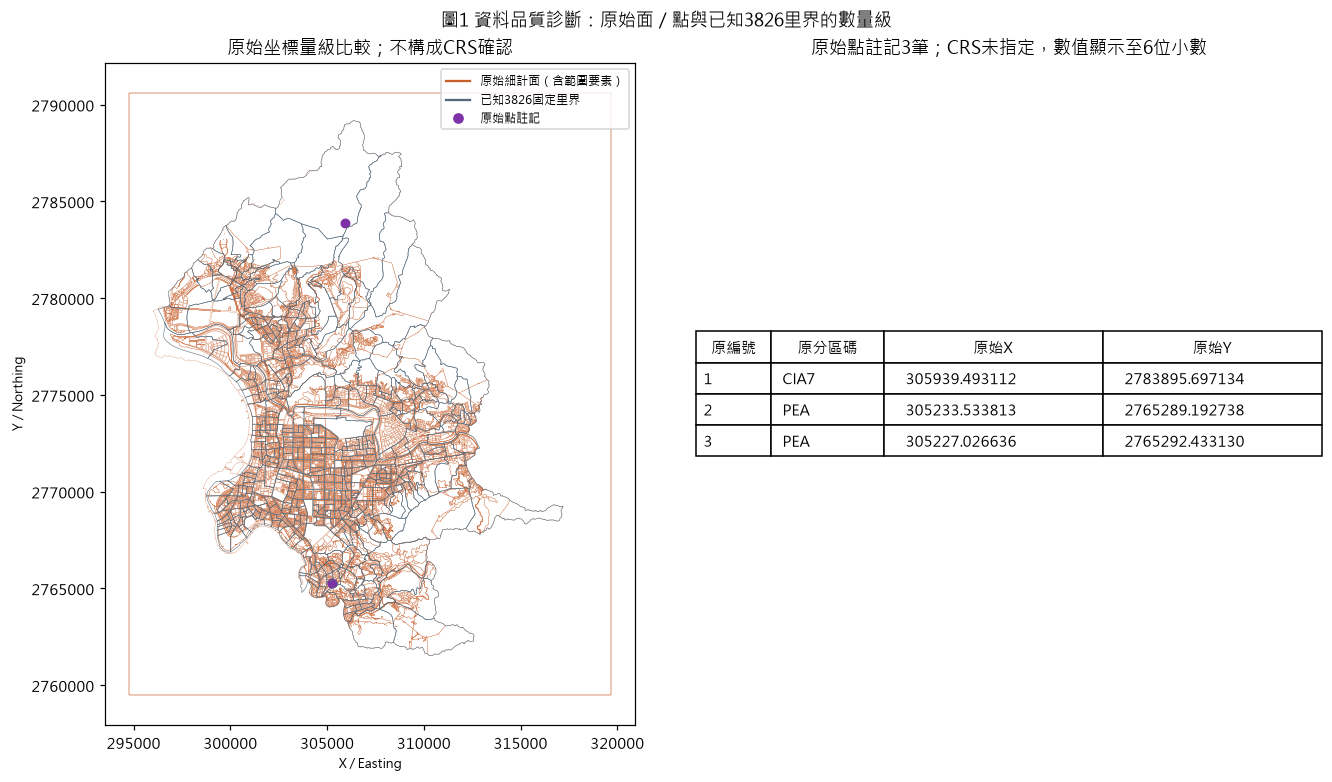

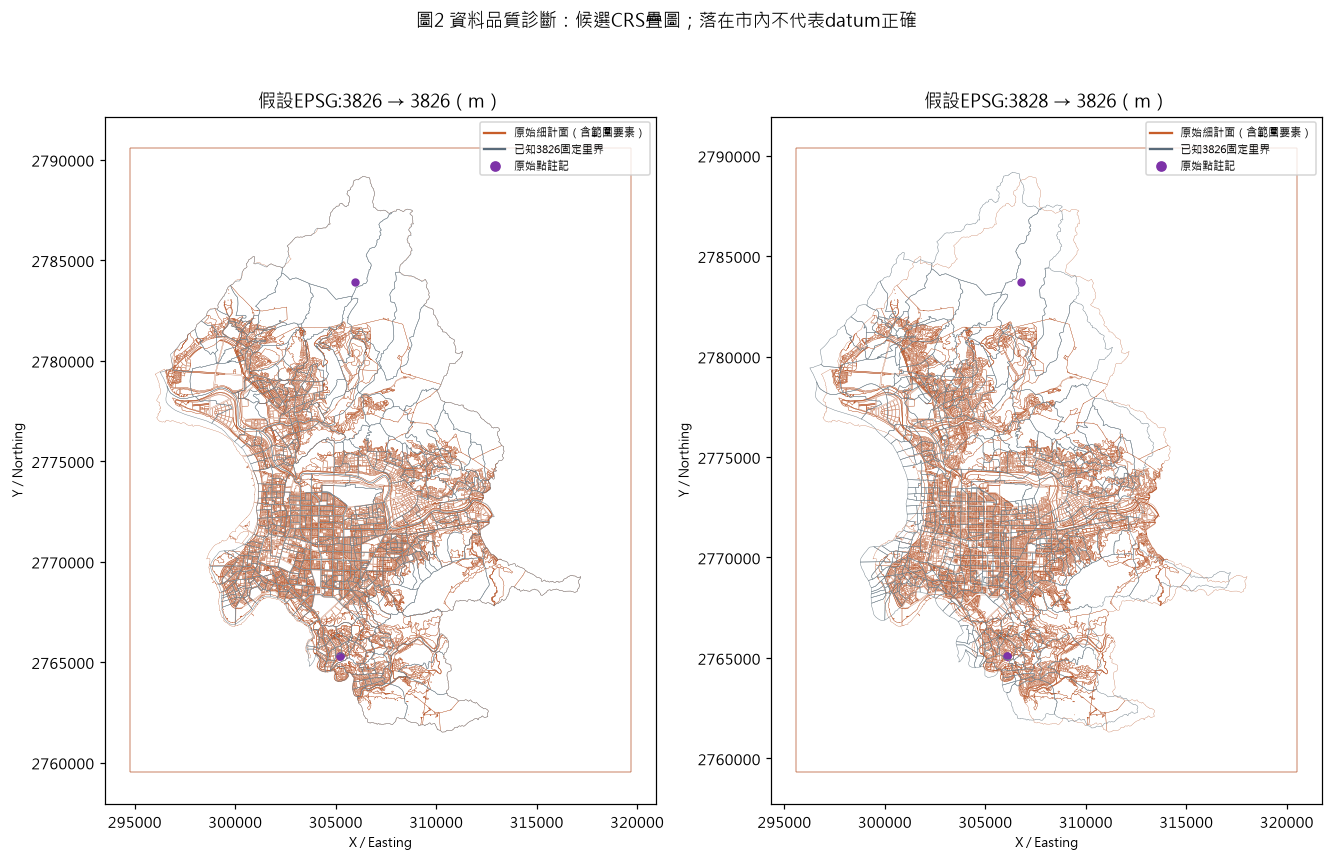

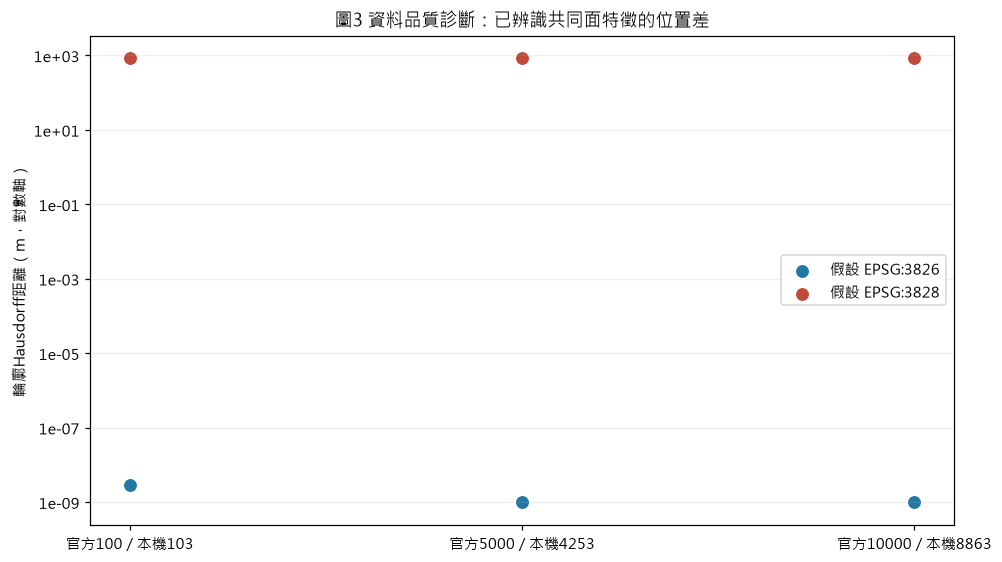

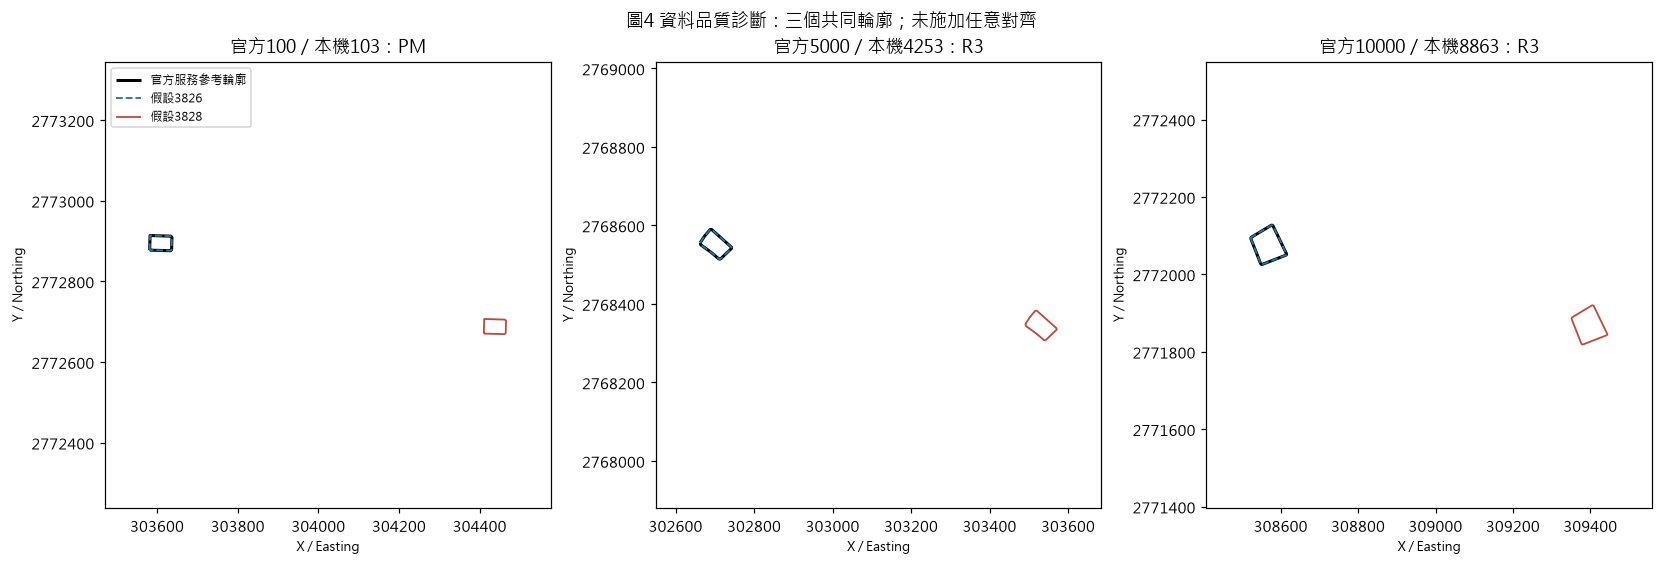

In [10]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter,NullFormatter
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
font=Path(os.environ['WINDIR'])/'Fonts/msjh.ttc';font_manager.fontManager.addfont(str(font))
family=font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams.update({'font.family':[family,'DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':110})
FIGURES=[]
def finish(fig,name):
    fig.savefig(TEMP/name,dpi=140,bbox_inches='tight');FIGURES.append('data/temp/unit14_validation/'+name)
    plt.show();plt.close(fig)
def axes_labels(ax,title):
    ax.set(title=title,xlabel='X / Easting',ylabel='Y / Northing');ax.ticklabel_format(style='plain',useOffset=False);ax.set_aspect('equal')
fig,axes=plt.subplots(1,2,figsize=(12,7),constrained_layout=True)
layers['細計-面'].plot(ax=axes[0],facecolor='none',edgecolor='#c75d29',linewidth=.16)
village.boundary.plot(ax=axes[0],color='#586a7a',linewidth=.35)
layers['細計-文'].plot(ax=axes[0],color='#7d32a8',markersize=30)
axes_labels(axes[0],'原始坐標量級比較；不構成CRS確認')
from matplotlib.lines import Line2D
legend_handles=[Line2D([0],[0],color='#c75d29',label='原始細計面（含範圍要素）'),
                Line2D([0],[0],color='#586a7a',label='已知3826固定里界'),
                Line2D([0],[0],marker='o',color='#7d32a8',linestyle='none',label='原始點註記')]
axes[0].legend(handles=legend_handles,loc='upper right',fontsize=8)
xy=coordinates['細計-文'];axes[1].axis('off')
point_table=[[row['編號'],row['分區代碼'],f'{point.x:.6f}',f'{point.y:.6f}']
             for (_,row),point in zip(layers['細計-文'].iterrows(),layers['細計-文'].geometry)]
table=axes[1].table(cellText=point_table,colLabels=['原編號','原分區碼','原始X','原始Y'],
                     loc='center',cellLoc='left',colWidths=[.12,.18,.35,.35])
table.auto_set_font_size(False);table.set_fontsize(10);table.scale(1,1.8)
axes[1].set_title('原始點註記3筆；CRS未指定，數值顯示至6位小數')
fig.suptitle('圖1 資料品質診斷：原始面／點與已知3826里界的數量級')
finish(fig,'fig01_raw_coordinate_ranges.png')

fig,axes=plt.subplots(1,2,figsize=(12,8),constrained_layout=True)
for ax,epsg in zip(axes,[3826,3828]):
    village.boundary.plot(ax=ax,color='#71808a',linewidth=.3)
    diagnostic[epsg]['細計-面'].plot(ax=ax,facecolor='none',edgecolor='#b75529',linewidth=.18)
    diagnostic[epsg]['細計-文'].plot(ax=ax,color='#7d32a8',markersize=20)
    axes_labels(ax,f'假設EPSG:{epsg} → 3826（m）')
    ax.legend(handles=legend_handles,loc='upper right',fontsize=7)
fig.suptitle('圖2 資料品質診斷：候選CRS疊圖；落在市內不代表datum正確')
finish(fig,'fig02_candidate_CRS_overlays.png')

fig,ax=plt.subplots(figsize=(9,5),constrained_layout=True)
for epsg,color in [(3826,'#2476a3'),(3828,'#c04b3b')]:
    values=residuals.loc[residuals.candidate_EPSG.eq(epsg)]
    ax.scatter(np.arange(len(values)),values.Hausdorff_distance_m,color=color,s=55,label=f'假設 EPSG:{epsg}')
ax.set_yscale('log');ax.yaxis.set_major_formatter(FuncFormatter(lambda value,position:f'{value:.0e}'))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xticks(range(len(controls)),[f"官方{c['service_number']} / 本機{c['local_number']}" for c in controls])
ax.set(ylabel='輪廓Hausdorff距離（m，對數軸）',title='圖3 資料品質診斷：已辨識共同面特徵的位置差')
ax.legend();ax.grid(axis='y',alpha=.2)
finish(fig,'fig03_control_position_residuals.png')

fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
for ax,c in zip(axes,controls):
    official=c['reference_geometry']
    gpd.GeoSeries([official],crs=3826).boundary.plot(ax=ax,color='black',linewidth=2,label='官方服務參考輪廓')
    for epsg,color,style in [(3826,'#2476a3','--'),(3828,'#c04b3b','-')]:
        g=diagnostic[epsg]['細計-面'].geometry.loc[c['local_index']]
        gpd.GeoSeries([g],crs=3826).boundary.plot(ax=ax,color=color,linewidth=1.2,linestyle=style,label=f'假設{epsg}')
    all_bounds=np.asarray([official.bounds]+[diagnostic[epsg]['細計-面'].geometry.loc[c['local_index']].bounds for epsg in [3826,3828]])
    low=all_bounds[:,:2].min(axis=0);high=all_bounds[:,2:].max(axis=0)
    center=(low+high)/2;span=float((high-low).max())*1.25
    ax.set_xlim(center[0]-span/2,center[0]+span/2);ax.set_ylim(center[1]-span/2,center[1]+span/2)
    axes_labels(ax,f"官方{c['service_number']}／本機{c['local_number']}：{c['code']}")
axes[0].legend(loc='upper left',fontsize=8)
fig.suptitle('圖4 資料品質診斷：三個共同輪廓；未施加任意對齊')
finish(fig,'fig04_common_feature_positions.png')


## 10. Historical Applicability, Main versus Detailed Plan and Unit 1.5 Handoff
**時間結論：** 官方頁內容標示2025年1月，資源／DBF寫入為2026-04-09；本機六檔與該官方資源完全相同。
各計畫法定生效日與本機原下載日期未知。本次未找到2024／2025各一份可直接使用的全市細計歷史SHP；個案公告／通盤檢討資料不等於全市年度快照。
只能提出固定時點規劃環境快照候選，保留2024事後快照與2025年內變動／後續修訂可能性；不得當作事前環境、無洩漏預測或因果證據。

**主要／細部比較：** [官方都市計畫法第15／22條](https://laws.gov.taipei/law/LawSearch/LawChapterArticle/FL003591?chapterno=2)分別描述整體土地使用配置／主要系統與較細的分區管制／地區設施。
法定圖面比例尺下限分別1:10,000及1:1,200，這不是本SHP實際測量精度。本機細計面15,518列，官方主計面3,840、主計點3,824；主計較少面不代表可完整替代細計。
兩種下載均缺PRJ／CPG與逐要素生效日期，主要計畫沒有更完整CRS優勢，不在本階段替換或混合兩層級面積。

**Unit 0.5既有品質紀錄（未於本單元正式修復或分類）：** 細計面15,508 Polygon＋10 MultiPolygon，143無效，5組11列相同WKB，97種圖層／260種分區代碼，4筆使用分區空白，含計畫／規劃範圍。部分重疊及覆蓋仍待Unit 1.5驗證；點註記不得充當面分區。
官方服務renderer及欄位metadata可供Unit 1.5查證對照，但不是完整法律分類碼表，亦不得將其現行編號當跨版穩定鍵。

**CRS證據分級：** 面圖層為 **B Strongly supported working CRS，候選EPSG:3826**：同源官方服務來源宣告3826，3個屬性／輪廓可唯一辨識的共同面在3826假設下近數值一致，3828假設產生明顯偏移；但仍缺本機下載圖資自身投影定義或提供機關明確版本聲明，不能列A。
點註記圖層為 **C Ambiguous CRS**：同包、坐標量級及同族服務支持3826候選，但未建立其3點與官方獨立已知點的明確對應，不能由面控制直接認證點datum。兩層均未正式指定CRS。

**後續條件／建議：** 建議保留現有細計面來源，待學生審查採用3826工作假設及固定快照限制後進行Unit 1.5；可先查屬性／幾何問題，正式面積或疊合須另授權並通過幾何／分類／重複與覆蓋審查。
沒有必要為處理方便改用同樣缺CRS的主計。若暫停B2，D原版仍可做事故分群及B1人口比較，但環境解釋範圍縮小；D改良版須重評環境特徵充分性，不能預設人口三變數已足夠。
本單元不替學生採用正式CRS、不修改原幾何、不修復／去重／分類／算面積，完成後停止，未進入Unit 1.5。


In [11]:
KNOWN_UNIT05={'polygon_features':15518,'Polygon':15508,'MultiPolygon':10,'invalid_polygon_features':143,
   'exact_WKB_duplicate_groups':5,'duplicate_group_rows':11,'raw_layer_categories':97,'raw_zoning_codes':260,'blank_use_labels':4}
show('表25：既有Unit 0.5品質紀錄；非本單元新修復結果',pd.DataFrame([KNOWN_UNIT05]))
assert len(layers['細計-面'])==KNOWN_UNIT05['polygon_features']
for name,g in layers.items():assert g.crs is None and g.geometry.to_wkb().equals(original_wkb[name])
verify(EXPECTED_SHA256)
result={'six_local_official_files_identical':True,'local_source_relationship_grade':'A for detailed ZIP bytes',
   'local_polygon_CRS_evidence_grade':'B','local_point_CRS_evidence_grade':'C','working_polygon_CRS_candidate':3826,
   'formal_local_CRS_confirmed':False,'independent_polygon_controls':len(controls),
   'official_polygon_samples_without_unique_local_shape':2,'point_controls_established':False,
   'control_residuals':residuals.to_dict('records'),'candidate_position_shifts':shifts,
   'official_main_polygon_rows':len(main_layers['主計圖-面']),'official_main_point_rows':len(main_layers['主計圖-文']),
   'official_service_polygon_rows':json.loads(evidence.read('layer2_count.json'))['count'],
   'content_date_on_page':'2025-01','official_resource_update_date':'2026-04-09','plan_effective_dates':'unconfirmed',
   'formal_GIS_exports':0,'geometry_repairs':0,'zoning_classifications':0,'area_calculations':0,'formal_overlays':0,
   'Unit_1_3_rerun':False,'crosswalk_changed':False,'Tangbu_included_main':True,'Tangbu_exclusion_sensitivity_required':False,
   'diagnostic_figures':FIGURES,'Unit_1_5_started':False}
(TEMP/'validation_summary.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
print(result)


**表25：既有Unit 0.5品質紀錄；非本單元新修復結果**

,polygon_features,Polygon,MultiPolygon,invalid_polygon_features,exact_WKB_duplicate_groups,duplicate_group_rows,raw_layer_categories,raw_zoning_codes,blank_use_labels
0,15518,15508,10,143,5,11,97,260,4


{'six_local_official_files_identical': True, 'local_source_relationship_grade': 'A for detailed ZIP bytes', 'local_polygon_CRS_evidence_grade': 'B', 'local_point_CRS_evidence_grade': 'C', 'working_polygon_CRS_candidate': 3826, 'formal_local_CRS_confirmed': False, 'independent_polygon_controls': 3, 'official_polygon_samples_without_unique_local_shape': 2, 'point_controls_established': False, 'control_residuals': [{'candidate_EPSG': 3826, 'service_objectid': 15393, 'service_number': '100', 'local_number': '103', 'zoning_code': 'PM', 'Hausdorff_distance_m': 2.794573987870897e-09, 'projection_operation_accuracy_m': 0.0}, {'candidate_EPSG': 3826, 'service_objectid': 20289, 'service_number': '5000', 'local_number': '4253', 'zoning_code': 'R3', 'Hausdorff_distance_m': 9.757381988596294e-10, 'projection_operation_accuracy_m': 0.0}, {'candidate_EPSG': 3826, 'service_objectid': 25289, 'service_number': '10000', 'local_number': '8863', 'zoning_code': 'R3', 'Hausdorff_distance_m': 9.94652945701676